# Active Subspaces of Fatigue Loads on a Floating Offshore Wind Turbine

__Andrew Glaws__, __Peter Graf__ and __Ryan Howard__

Data: __Peter Graf__, National Renewable Energy Laboratory (NREL), from the study in [[3]][R3]. Redistributed under CC BY 4.0 (see `DATA.md`).

<br>

This notebook applies active subspaces to fatigue loads that NREL computed with its wind turbine simulator FAST, using the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy, scipy and matplotlib (see the repository's `requirements.txt`), and takes about a minute.

The active-subspace analysis in this notebook is not published. [[3]][R3] is the source of the model and the data only: it compares grid-based and Monte Carlo estimates of long-term fatigue loads, and it does not use active subspaces.

### Introduction

For fixed-bottom offshore wind turbines, the design standard IEC 61400-3 specifies the load cases used to estimate long-term fatigue loads. Floating offshore wind turbines have no such standard yet. They are also more sensitive to misalignment of wind and waves, because a floating platform is more compliant and has little side-to-side damping [[3]][R3]. Their fatigue loads must therefore be estimated over a larger space of wind and wave conditions. Each condition needs a simulation of turbulent wind, waves and the turbine's response, and the number of simulations a grid-based study needs grows exponentially with the number of conditions. One way around this is dimension reduction: find the few directions in the space of conditions along which a load changes, and study the load along those. In this notebook we discuss the _active subspaces_ method of dimension reduction and apply it to seven loads on a floating offshore wind turbine.

### Active Subspaces

Consider our scalar quantity of interest as a function of normalized inputs, $f(\mathbf x)$. The active subspaces methodology looks for the most 'important' directions in the input space (the span of which is the active subspace), along which $f$ tends to change more than in the orthogonal directions. If $f$ is reasonably flat in the orthogonal directions, it could be reasonable to examine it only in the active subspace. The method is based on the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\,\nabla f(\mathbf x)^T\rho(\mathbf x)\ d\mathbf x,
$$

where $\nabla f(\mathbf x)$ is the gradient of $f$ with respect to the inputs $\mathbf x$ and $\rho(\mathbf x)$ is a probability density function. $\mathbf C$ is positive semidefinite, so it has an eigendecomposition $\mathbf C = \mathbf W\Lambda\mathbf W^T$, where $\Lambda$ is a diagonal matrix containing $\mathbf C$'s eigenvalues in descending order and $\mathbf W$'s columns are the corresponding eigenvectors. We can partition the decomposition as

$$
\mathbf W = \left[\begin{matrix}\mathbf W_1 & \mathbf W_2\end{matrix}\right],\ \Lambda = \left[\begin{matrix}\Lambda_1 & \\ & \Lambda_2\end{matrix}\right],
$$

where $\Lambda_1$ contains the first $n$ eigenvalues and $\mathbf W_1$ the corresponding eigenvectors. Each eigenvalue quantifies how much $f$ changes, on average, along the direction defined by the corresponding eigenvector: $\lambda_i = \int(\mathbf w_i^T\nabla f(\mathbf x))^2\rho(\mathbf x)\,d\mathbf x$. If the first $n$ eigenvalues are large compared to the rest, $f$ will likely be relatively flat along the directions in $\mathbf W_2$. The active variables are $\mathbf y = \mathbf W_1^T\mathbf x$. In practice $\mathbf C$ is estimated from samples, and a large gap between $\lambda_n$ and $\lambda_{n+1}$ means the $n$-dimensional subspace can be estimated accurately [[1]][R1], [[2]][R2].

### The model

[[3]][R3] simulates the OC3 Hywind spar-buoy design, a floating offshore wind turbine. Each sample is one 10-minute simulation of normal operation (IEC 61400-3 design load case 1.2). TurbSim generates the turbulent wind (IEC class A normal turbulence model, power-law shear with exponent 0.14); HydroDyn generates the waves from a JONSWAP spectrum set by the significant wave height and the peak period; and FAST version 7 computes the turbine's response. NREL's WISDEM framework drew the samples and ran the simulations. The wind and wave conditions follow distributions fitted to NOAA National Data Buoy Center data for a representative East Coast site [[3]][R3] §2–3.

**Inputs.** There are 5 inputs. The table lists them in the data's column order, with the distributions of [[3]][R3] §2.

Column | Symbol | Meaning | Distribution [[3]][R3] | Stored value
:------|:------:|:--------|:-------------|:------------
`Vhub` | $V_{hub}$ | hub-height wind speed (m/s) | Weibull | $2u-1$
`Hs` | $H_s$ | significant wave height (m) | gamma conditioned on $V_{hub}$ and $\theta_w$ | $2u-1$
`WaveDir` | $\theta_w$ | wave direction with respect to the wind (rad) | von Mises conditioned on $V_{hub}$ | $\theta_w/\pi$
`Tp` | $T_p$ | peak spectral wave period (s) | gamma conditioned on $V_{hub}$ and $H_s$ | $2u-1$
`PlatformDir` | $\theta_p$ | wind direction with respect to the fixed platform orientation (rad) | von Mises conditioned on $V_{hub}$ | $\theta_p/\pi$

The file does not store the physical values, and two encodings are mixed:

- **`Vhub`, `Hs` and `Tp` are probability coordinates**, $2u-1$, where $u$ is the input's cumulative distribution function evaluated at the sample (for `Hs` and `Tp`, the conditional one, given the inputs they depend on). They are uniform on $[-1, 1]$. A unit change in them is a change of half the probability range, not of a fixed number of m/s, m or s.
- **`WaveDir` and `PlatformDir` are angles in units of $\pi$ rad**, from von Mises draws that are not wrapped to $[-\pi, \pi]$. That is why some of them lie outside $[-1, 1]$. They keep the dependence on wind speed that [[3]][R3] describes: the spread of `WaveDir` shrinks as the wind speed grows.

[[3]][R3] gives the distribution parameters of its 4-input study only (p. 3), not those of the 5-input study these data come from.

**Outputs.** FAST computes many load histories; we examine 7. Each output is a short-term _damage equivalent load_ (DEL): the amplitude of a 1 Hz sinusoidal load that does the same fatigue damage as the simulated 10-minute load history, computed by rainflow counting with a fixed mean of zero and material (S-N curve) exponent $m = 4$, which is what the prefix `rf4` means [[3]][R3] §2–3.

Column | Load
:------|:----
`rf4_RootMxc1` | blade 1 root, in-plane ("edgewise") bending moment
`rf4_RootMyc1` | blade 1 root, out-of-plane (flapwise) bending moment
`rf4_TwrBsMxt` | tower base, side-to-side bending moment
`rf4_TwrBsMyt` | tower base, fore-aft bending moment
`rf4_Anch1Ten`, `rf4_Anch2Ten`, `rf4_Anch3Ten` | tension at the anchor of mooring line 1, 2, 3

[[3]][R3] names `RootMxc1`, `TwrBsMxt` and `Anch1Ten` as above; the meanings of `RootMyc1` and `TwrBsMyt` follow FAST's channel names. [[3]][R3] uses $m = 4$ for metal parts such as the tower and $m = 10$ for composite parts such as the blades. Here every output, the blade-root moments included, uses $m = 4$. The units are unconfirmed: presumably FAST's channel units, kN·m for the moments and kN for the tensions, but neither [[3]][R3] nor the data state them.

**Samples.** The data set has 50,000 input/output pairs, a subset of the 500,000 Monte Carlo samples of the 5-input study in [[3]][R3] §4.3. (The 2016 version of this notebook said "nearly 500,000 pairs". That described the first data file, `windData500k.mat`, which was removed from the repository in July 2016 and survives only in its history.) There are no gradients.

### References

[[1]][R1] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[[2]][R2] P.G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, 2015. doi:10.1137/1.9781611973860

[[3]][R3] P.A. Graf, G. Stewart, M. Lackner, K. Dykes, and P. Veers. _High-throughput computation and the applicability of Monte Carlo integration in fatigue load estimation of floating offshore wind turbines_. Wind Energy, 19(5):861–872, 2016. doi:10.1002/we.1870 (NREL/JA-2C00-62929). Section and page numbers here refer to the accepted manuscript.

[R1]: https://doi.org/10.1137/130916138
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1002/we.1870

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077. The data were generated by Peter Graf at the National Renewable Energy Laboratory.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

t_start = time.perf_counter()
rng = np.random.default_rng(2016)        # the only source of randomness in this notebook

### Loading the data

`NRELwind_testing.txt` is a CSV file with one header row. Column 0 is the run number, columns 1–5 the inputs and columns 6–12 the outputs. We print the range of each input, its standard deviation ($1/\sqrt 3 = 0.577$ for a uniform variable on $[-1, 1]$) and how many values lie outside $[-1, 1]$.

In [2]:
fname = 'NRELwind_testing.txt'
with open(fname) as fh:
    header = fh.readline().strip().split(',')
data = np.loadtxt(fname, delimiter=',', skiprows=1)
X, F = data[:, 1:6], data[:, 6:]
in_labels, out_labels = header[1:6], header[6:]
M, m = X.shape
print(f'{M} samples (runs {data[0, 0]:.0f} to {data[-1, 0]:.0f}), {m} inputs, {F.shape[1]} outputs')
print(f'{"input":>12}{"min":>9}{"max":>9}{"std":>8}{"< -1":>7}{"> 1":>6}')
for j, name in enumerate(in_labels):
    x = X[:, j]
    print(f'{name:>12}{x.min():9.3f}{x.max():9.3f}{x.std():8.3f}{(x < -1).sum():7d}{(x > 1).sum():6d}')
print(f'rows with an input outside [-1, 1]: {(np.abs(X) > 1).any(axis=1).sum()}')

50000 samples (runs 1 to 50000), 5 inputs, 7 outputs
       input      min      max     std   < -1   > 1
        Vhub   -1.000    1.000   0.578      0     0
          Hs   -1.000    1.000   0.576      0     0
     WaveDir   -1.103    1.014   0.489    435     6
          Tp   -1.000    1.000   0.579      0     0
 PlatformDir   -0.953    1.046   0.452      0   284
rows with an input outside [-1, 1]: 724


The three probability coordinates fill $[-1, 1]$ with the standard deviation of a uniform variable, and the two angles are bell-shaped and spill over. To see the dependence on wind speed, we split the samples into five groups by `Vhub` (lowest wind speeds first) and print the mean and standard deviation of the other inputs in each group. `Hs` and `Tp` do not change across the groups, although their distributions depend on $V_{hub}$: they are stored as conditional probabilities. The spread of `WaveDir` shrinks as the wind speed grows.

In [3]:
group = np.searchsorted(np.quantile(X[:, 0], [.2, .4, .6, .8]), X[:, 0])   # Vhub quintile, 0 to 4
print('mean / std by Vhub quintile')
for j in range(1, m):
    print(f'{in_labels[j]:>12}' + ''.join(f'{X[group == k, j].mean():8.3f} /{X[group == k, j].std():6.3f}'
                                          for k in range(5)))

mean / std by Vhub quintile
          Hs  -0.001 / 0.576  -0.006 / 0.577   0.001 / 0.575  -0.006 / 0.575   0.002 / 0.576
     WaveDir  -0.069 / 0.539  -0.040 / 0.514  -0.026 / 0.485  -0.003 / 0.462   0.024 / 0.434
          Tp  -0.005 / 0.580   0.003 / 0.579   0.000 / 0.577   0.008 / 0.577  -0.013 / 0.580
 PlatformDir   0.043 / 0.452   0.045 / 0.448   0.040 / 0.456   0.055 / 0.453   0.048 / 0.451


### The input space

active_subspaces works in normalized coordinates on an input space. The reference space $[-1, 1]^5$ does not contain the data, and v1 refuses it:

In [4]:
try:
    ac.local_linear_gradients(X=X, f=F[:, 0], space=ac.Uniform.reference(m, names=in_labels), p=60)
except ac.InputError as e:
    print(e)
    print(f'n_outside = {e.details["n_outside"]}, first input outside: {e.details["name"]}')

X: 724 of 50000 rows lie outside the support; first: row 7, input 'PlatformDir' (column 4) = 1.0389279698213882 > upper 1.0 [input.out_of_space]
n_outside = 724, first input outside: PlatformDir


We therefore use the smallest box that contains both $[-1, 1]^5$ and the data. For `Vhub`, `Hs` and `Tp` it is $[-1, 1]$, so their normalized coordinates are the stored values. For `WaveDir` and `PlatformDir` it is slightly wider, so their normalized coordinates are the stored ones scaled by $2/(\text{upper} - \text{lower})$ (printed) and shifted. The box only fixes the normalization: we never sample from it, and the gradients below are estimated at data points, so $\hat{\mathbf C}$ averages over the distribution of the samples, not over the box.

In [5]:
space = ac.Uniform(lower=np.minimum(X.min(axis=0), -1), upper=np.maximum(X.max(axis=0), 1),
                   names=tuple(in_labels))
for name, lo, hi in zip(in_labels, space.lower, space.upper):
    print(f'{name:>12}: [{lo:7.4f}, {hi:7.4f}], scale 2/(upper - lower) = {2/(hi - lo):.3f}')

        Vhub: [-1.0000,  1.0000], scale 2/(upper - lower) = 1.000
          Hs: [-1.0000,  1.0000], scale 2/(upper - lower) = 1.000
     WaveDir: [-1.1026,  1.0137], scale 2/(upper - lower) = 0.945
          Tp: [-1.0000,  1.0000], scale 2/(upper - lower) = 1.000
 PlatformDir: [-1.0000,  1.0465], scale 2/(upper - lower) = 0.977


### Gradients and subspaces

Recall that the matrix $\mathbf C$ is based on the gradient of $f$. With gradients, we would estimate $\mathbf C$ by Monte Carlo: average $\nabla f\,\nabla f^T$ over samples drawn from $\rho$. These data have no gradients, so we estimate them: at each of 2,000 randomly chosen sample points (the _centers_), we fit a linear model by least squares to the 60 sample points nearest to it in normalized coordinates, the center included, and take the model's slope as the gradient there. (The 2016 notebook used the 2016 package's default, $\lceil 10\,m\ln m\rceil = 81$ centers, unseeded.) We then compute the active subspace of each output from its 2,000 gradients, with 100 bootstrap replicates for the eigenvalue and eigenvector intervals. The same centers serve all 7 outputs.

In [6]:
centers = rng.choice(M, 2000, replace=False)
mask = rng.choice(M, 10000, replace=False)       # points shown in the scatter plots
subs = []
for i, name in enumerate(out_labels):
    g = ac.local_linear_gradients(X=X, f=F[:, i], space=space, p=60, centers=centers, qoi=name)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        subs.append(ac.active_subspace(grads=g, nboot=100, bootstrap_vectors=2, rng=rng))
    for w in caught:
        print(f'{name}: {getattr(w.message, "code", w.category.__name__)}, eigenvector columns '
              f'{[c + 1 for c in getattr(w.message, "details", {}).get("columns", [])]}')
print(f'2000 gradients and a subspace per output: {time.perf_counter() - t_start:.0f} s so far\n')

print(f'{"output":>14}' + ''.join(f'{"lambda_" + str(k):>11}' for k in range(1, 6))
      + ''.join(f'{"l" + str(k) + "/l" + str(k + 1):>8}' for k in range(1, 5)))
for name, s in zip(out_labels, subs):
    lam = s.eigenvalues
    print(f'{name:>14}' + ''.join(f'{v:11.3e}' for v in lam) + ''.join(f'{r:8.1f}' for r in lam[:-1] / lam[1:]))
for k in (0, 1):
    print(f'\n{"w_" + str(k + 1):>14}' + ''.join(f'{name:>12}' for name in in_labels))
    for name, s in zip(out_labels, subs):
        print(f'{name:>14}' + ''.join(f'{v:12.3f}' for v in s.W[:, k]))

rf4_RootMxc1: accuracy.unaligned_replicates, eigenvector columns [2]


rf4_RootMyc1: accuracy.unaligned_replicates, eigenvector columns [2]


2000 gradients and a subspace per output: 25 s so far

        output   lambda_1   lambda_2   lambda_3   lambda_4   lambda_5   l1/l2   l2/l3   l3/l4   l4/l5
  rf4_RootMxc1  8.914e+05  4.194e+03  4.015e+03  3.837e+03  3.766e+03   212.5     1.0     1.0     1.0
  rf4_RootMyc1  4.190e+06  3.582e+04  3.246e+04  3.131e+04  3.010e+04   117.0     1.1     1.0     1.0
  rf4_TwrBsMxt  2.530e+08  2.011e+08  3.188e+07  4.445e+06  3.259e+06     1.3     6.3     7.2     1.4
  rf4_TwrBsMyt  8.369e+08  7.208e+07  3.732e+07  1.156e+07  9.649e+06    11.6     1.9     3.2     1.2
  rf4_Anch1Ten  6.151e+03  1.752e+03  1.182e+02  1.109e+02  1.005e+02     3.5    14.8     1.1     1.1
  rf4_Anch2Ten  1.459e+04  4.270e+03  2.093e+02  1.876e+02  1.714e+02     3.4    20.4     1.1     1.1
  rf4_Anch3Ten  1.491e+04  5.177e+03  2.559e+02  2.250e+02  2.071e+02     2.9    20.2     1.1     1.1

           w_1        Vhub          Hs     WaveDir          Tp PlatformDir
  rf4_RootMxc1       1.000      -0.001       0.006   

### Choosing the dimension

The 2016 notebook chose the dimensions 1, 1, 3, 3, 2, 2 and 2 "based on the eigenvalue decay", but not every choice had a gap behind it: for `rf4_TwrBsMxt`, $\lambda_1 \approx \lambda_2$ above. active_subspaces v1 has dimension rules, and `ac.dimension_criterion` evaluates one without changing the result. We print the dimension that each of four rules picks:

- **linear gap** (v1's default): the largest $\lambda_k - \lambda_{k+1}$;
- **log gap**: the largest ratio $\lambda_k/\lambda_{k+1}$;
- **RS**: the $k$ that minimizes $\varepsilon_k = (\lambda_1 + \cdots + \lambda_k)^{1/2}\,\hat\delta_k + (\lambda_{k+1} + \cdots + \lambda_m)^{1/2}$, where $\hat\delta_k$ is the bootstrap mean distance between the estimated and the replicate subspaces. It is the bound on the error of a response surface on $k$ active variables [[2]](https://doi.org/10.1137/1.9781611973860), without its constant;
- **ladle**: the ladle estimator of Luo and Li (2016), which combines the eigenvalues with the bootstrap variability of the eigenvectors.

We use the RS rule, the authors' choice: our goal is a response surface on the active variables. It reproduces the 2016 notebook's dimensions 1, 1, 3, 3, 2, 2, 2 (printed below), which are now chosen by a stated rule. We pass its choice to `ac.with_dimension` explicitly.

In [7]:
rules = {'linear gap': 'evg', 'log gap': ac.subspaces.EVG(gap='log'), 'RS': 'rs', 'ladle': 'li'}
print(f'{"output":>14}' + ''.join(f'{r:>12}' for r in rules) + '     RS criterion eps_1 ... eps_4')
dims = []
for name, s in zip(out_labels, subs):
    picks = {r: ac.dimension_criterion(s, rule=rule) for r, rule in rules.items()}
    dims.append(picks['RS'][2])
    print(f'{name:>14}' + ''.join(f'{p[2]:12d}' for p in picks.values())
          + '     ' + ' '.join(f'{v:9.4g}' for v in picks['RS'][1]))
subs_n = [ac.with_dimension(s, n) for s, n in zip(subs, dims)]
print(f'\ndimensions used: {dims}')

        output  linear gap     log gap          RS       ladle     RS criterion eps_1 ... eps_4
  rf4_RootMxc1           1           1           1           1         129.2     681.8       708     752.9
  rf4_RootMyc1           1           1           1           1         367.4      1071      1482      1334
  rf4_TwrBsMxt           2           3           3           3      1.71e+04      6701      3103      3603
  rf4_TwrBsMyt           1           1           3           3     1.167e+04      9133      5485      8485
  rf4_Anch1Ten           1           2           2           2         46.97     19.12     55.34     41.39
  rf4_Anch2Ten           1           2           2           2         71.43      25.3     66.37     65.43
  rf4_Anch3Ten           1           2           2           2         78.67     27.83     63.42     74.22

dimensions used: [1, 1, 3, 3, 2, 2, 2]


### Eigenvalues, eigenvectors and sufficient summary plots

For each output we plot, from left to right: the eigenvalues with their bootstrap range (min to max over the replicates, as in the 2016 plots), the chosen dimension marked; the first two eigenvectors with 95% bootstrap bands; and the _sufficient summary plots_ of the output against the first active variable and against the first two (on the 10,000 points of a fixed random subset). Eigenvector components are in normalized coordinates. For `Vhub`, `Hs` and `Tp` a component measures sensitivity to the input's probability coordinate; for the angles, sensitivity per $\pi$ rad, times the box scale printed above.

Eigenvector signs are arbitrary. v1 makes each eigenvector's largest component positive, while the 2016 package made the first component positive. So for the anchor tensions, $\mathbf w_1$ points along $+$`PlatformDir` here and along $-$`PlatformDir` in the 2016 notebook, and their one-dimensional summary plots are mirror images of the 2016 ones.

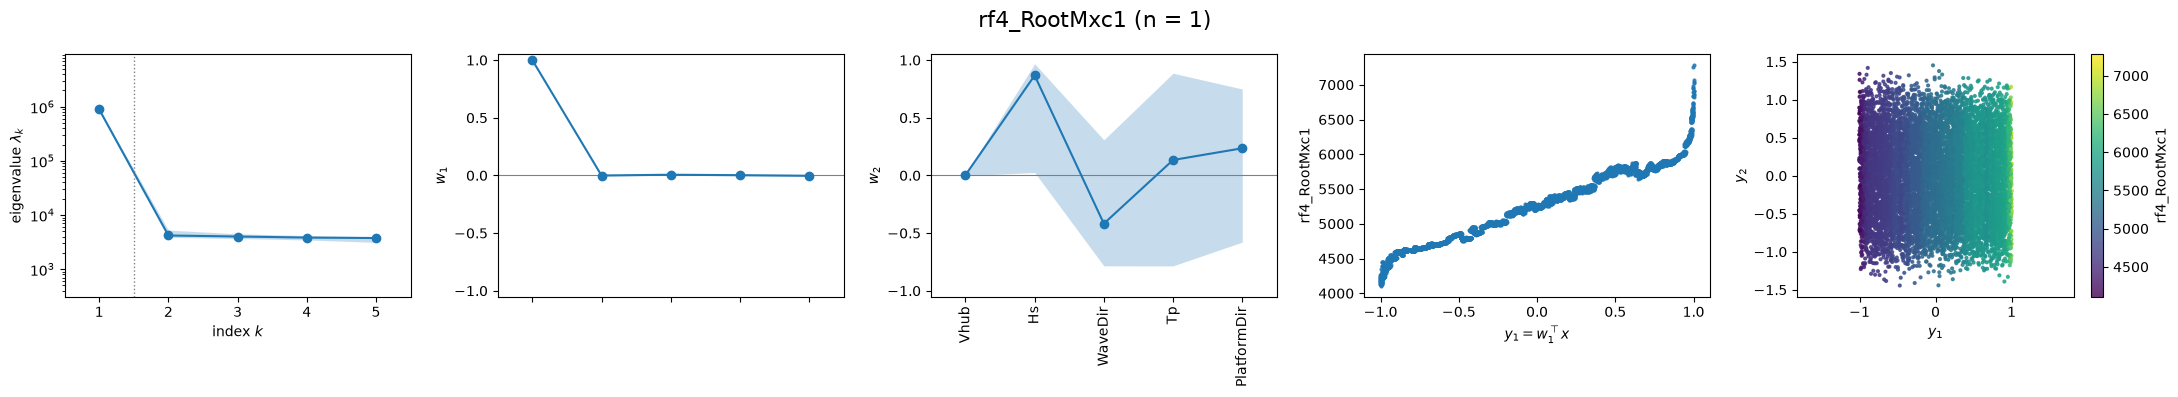

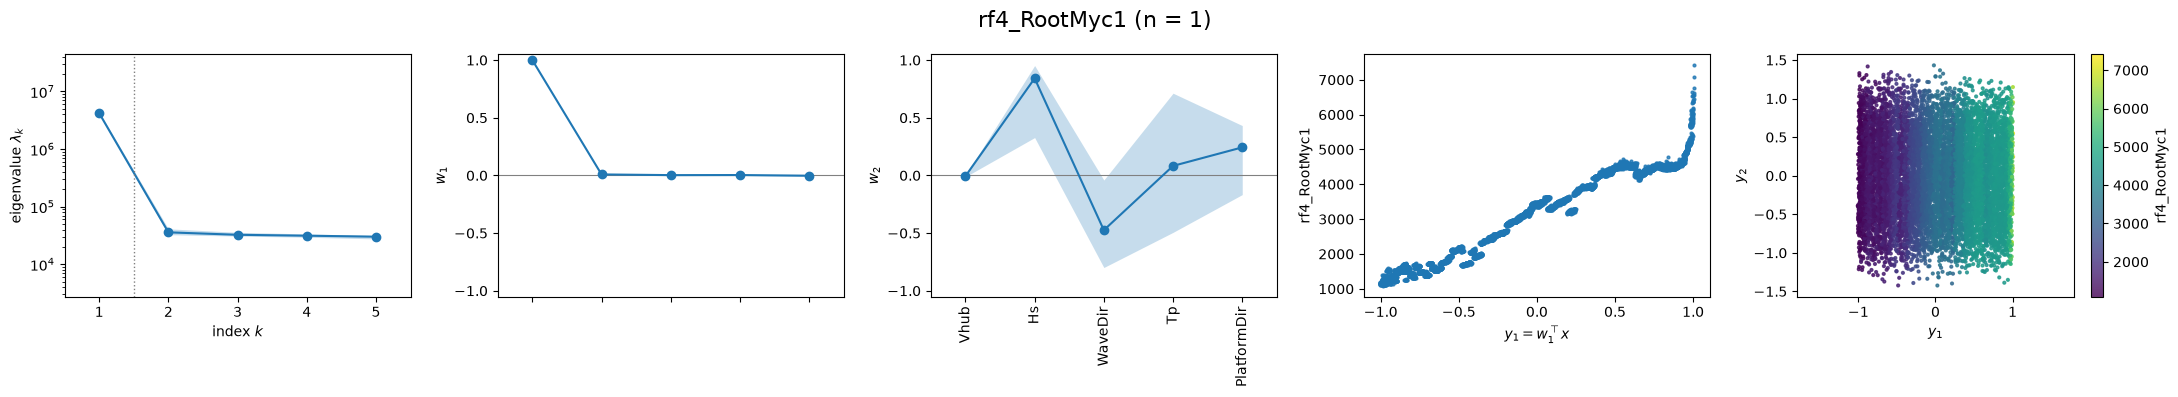

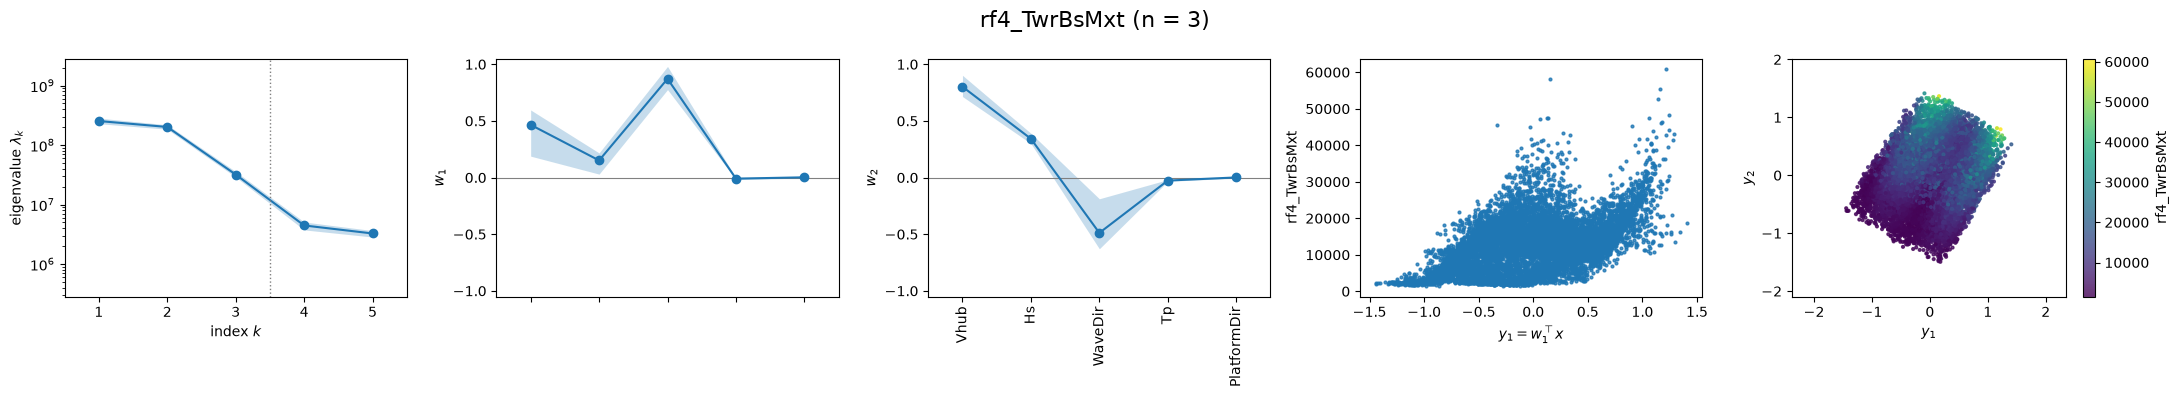

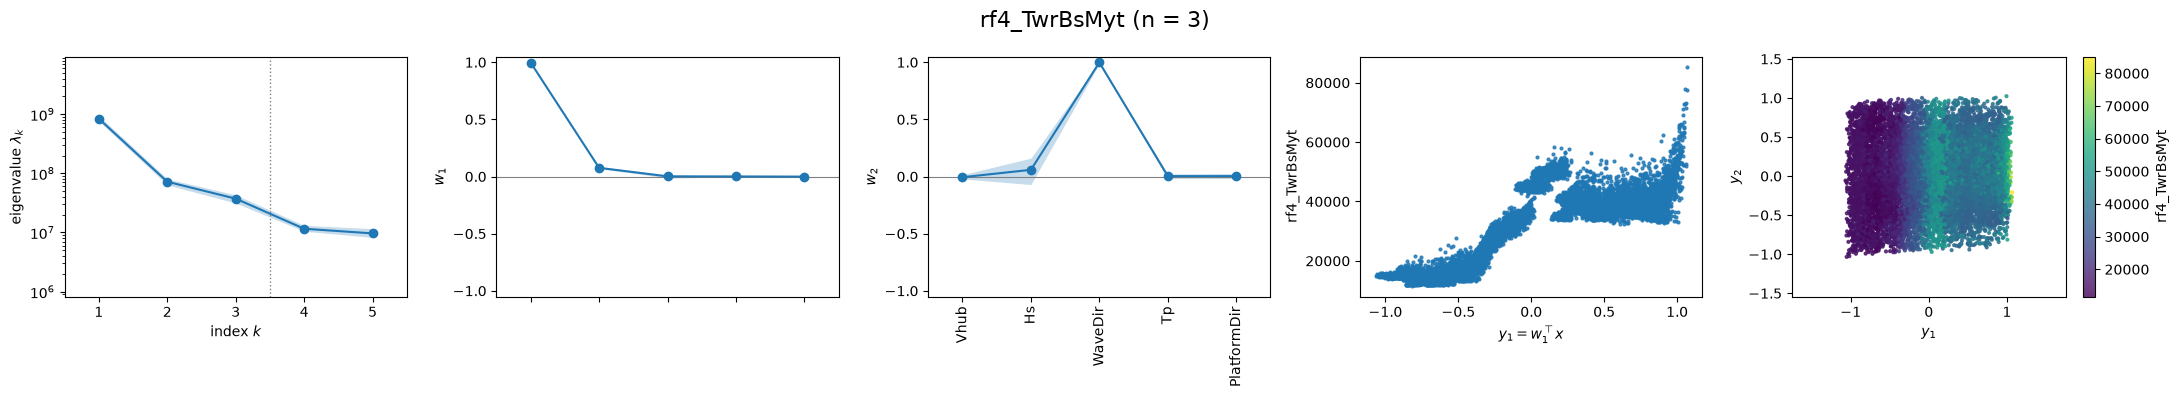

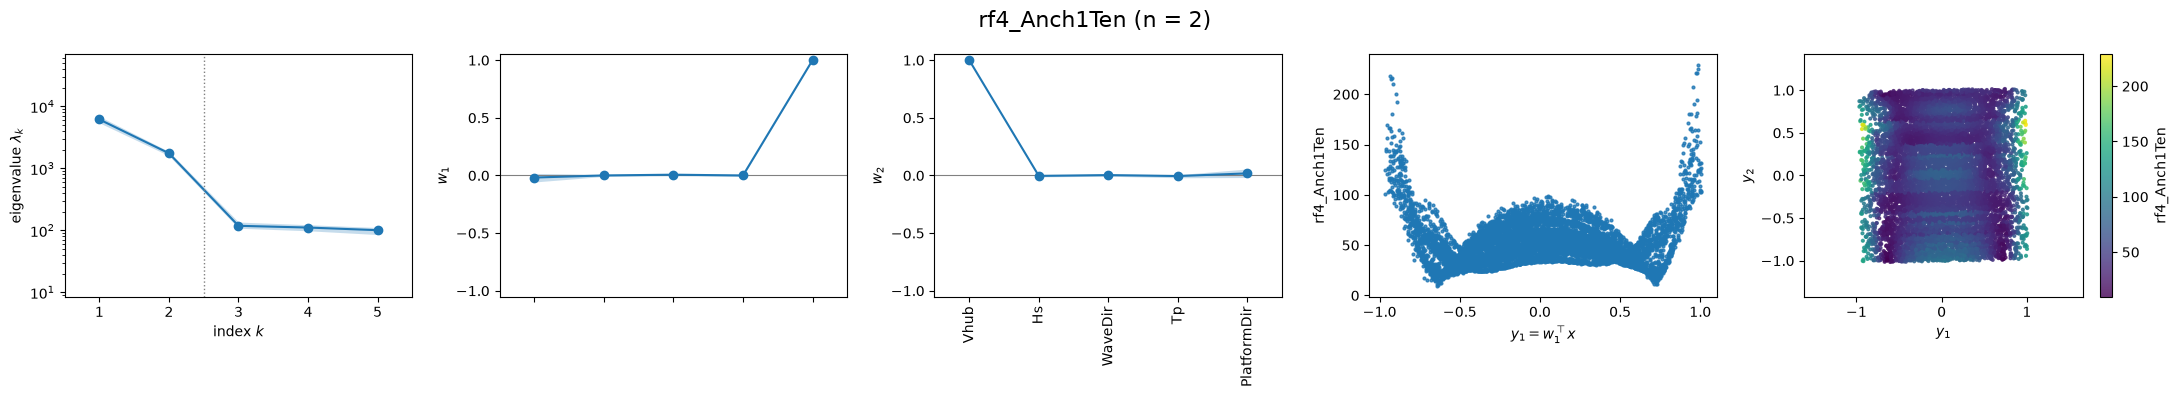

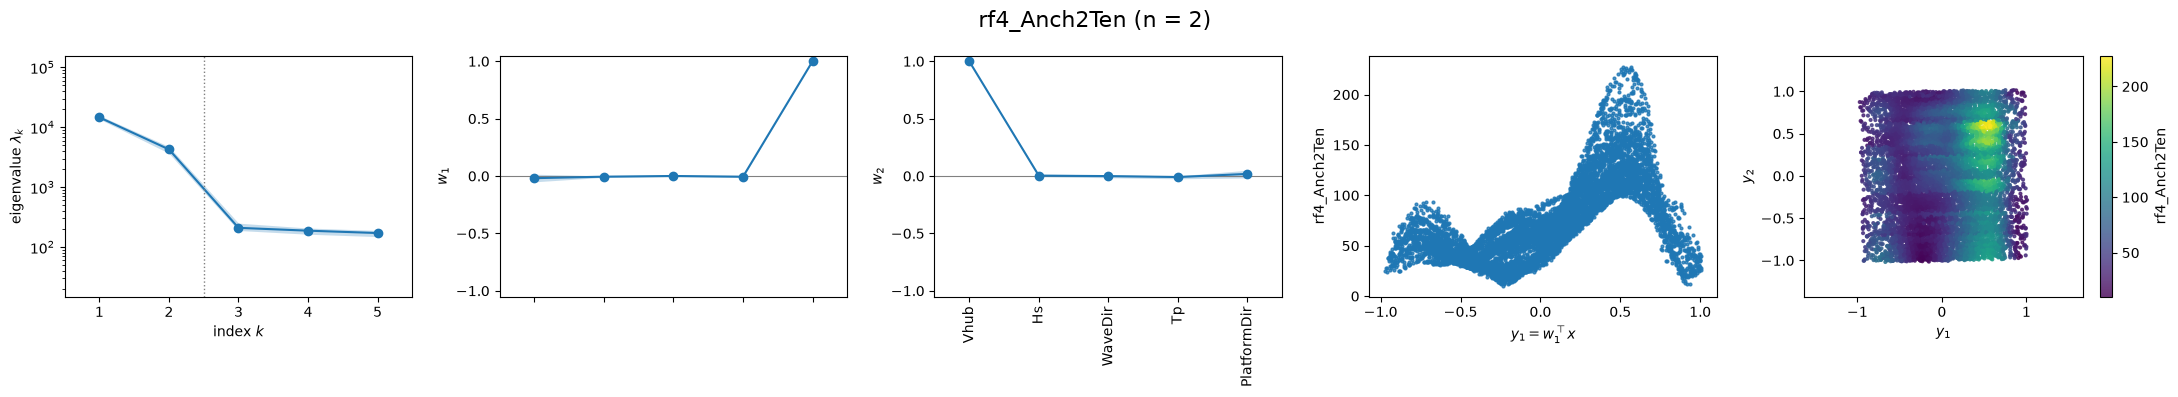

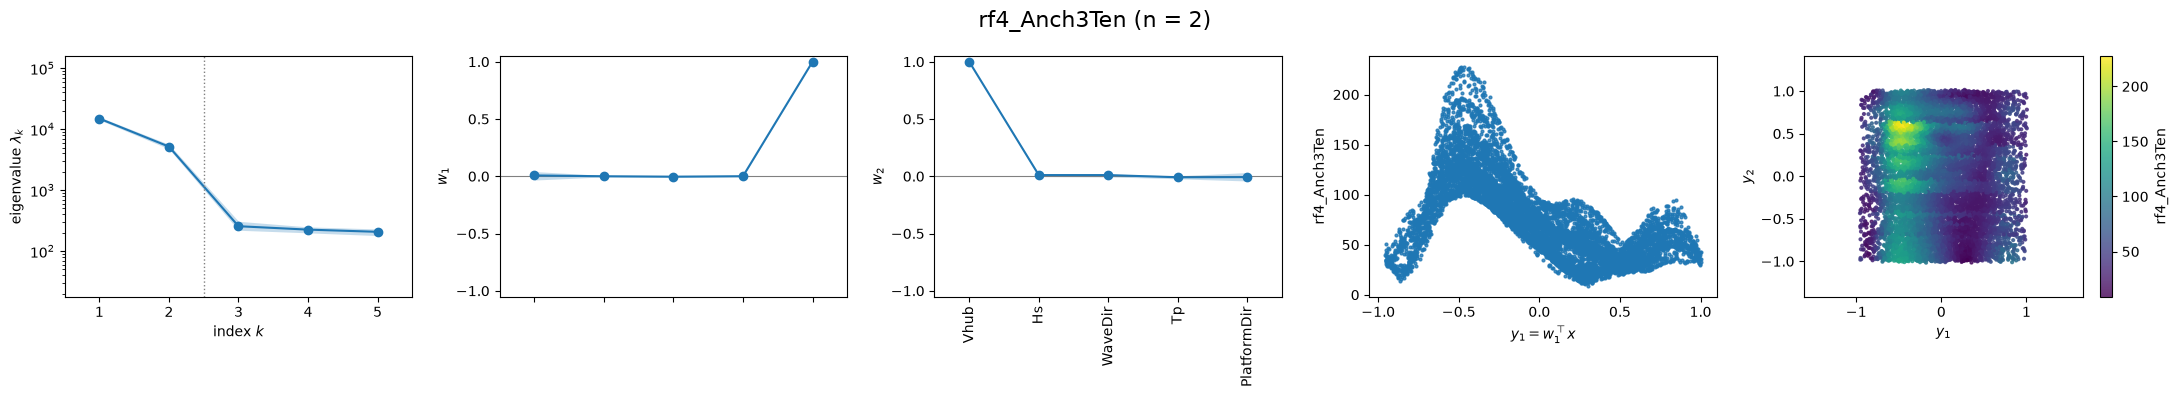

In [8]:
for i, name in enumerate(out_labels):
    fig, axes = plt.subplots(1, 5, figsize=(22, 4))
    s2 = ac.with_dimension(subs[i], 2)
    ac.plotting.plot_eigenvalues(subs_n[i], interval='minmax', ax=axes[0])
    ac.plotting.plot_eigenvectors(s2, indices=[0, 1], interval='percentile', ax=axes[1:3])
    for d, ax in [(1, axes[3]), (2, axes[4])]:
        ac.plotting.plot_sufficient_summary(s2, X=X[mask], f=F[mask, i], dims=d, qoi_label=name, ax=ax,
                                            scatter_kw={'s': 4})
    fig.suptitle(f'{name} (n = {dims[i]})', fontsize=16)
    fig.tight_layout()
    plt.show()

The eigenvectors measure global sensitivity: components of larger magnitude mark inputs to which the output is more sensitive. Using the numbers printed above:

- **Blade-root moments** (`rf4_RootMxc1`, `rf4_RootMyc1`). $\mathbf w_1$ is the `Vhub` axis (component 1.000), with $\lambda_1/\lambda_2$ = 212.5 and 117.0. Both loads are nearly functions of the wind speed's probability coordinate alone, as the tight one-dimensional summary plots show. The other four eigenvalues are nearly equal, so $\mathbf w_2$ is not determined: v1 warns `accuracy.unaligned_replicates` for it, and its bands are wide. This agrees with [[3]](https://doi.org/10.1002/we.1870) Fig. 7 for `RootMxc1`: coarsening the grid in $H_s$ barely changes the fatigue estimate, while coarsening it in $V_{hub}$ moves it. Fig. 7 also shows grids coarsened in `PlatformDir` moving the estimate, which these eigenvectors do not explain.
- **Tower-base fore-aft moment** (`rf4_TwrBsMyt`). $\mathbf w_1$ is again nearly the `Vhub` axis (0.997) and $\mathbf w_2$ the `WaveDir` axis (0.998), with $\lambda_1/\lambda_2$ = 11.6.
- **Tower-base side-to-side moment** (`rf4_TwrBsMxt`). This is the one output with an oblique active direction: $\mathbf w_1$ has components 0.466 on `Vhub` and 0.872 on `WaveDir`. But $\lambda_1/\lambda_2$ = 1.3, so $\mathbf w_1$ and $\mathbf w_2$ are not well separated (see their bands); together they span mostly `Vhub` and `WaveDir`. The load depends on the misalignment of wind and waves as well as on the wind speed, as [[3]](https://doi.org/10.1002/we.1870) (p. 1) expects from a floating platform's low side-to-side damping.
- **Anchor tensions** (`rf4_Anch1Ten`, `rf4_Anch2Ten`, `rf4_Anch3Ten`). $\mathbf w_1$ is the `PlatformDir` axis and $\mathbf w_2$ the `Vhub` axis (components 1.000), and $\lambda_2/\lambda_3$ = 14.8, 20.4 and 20.2. The two-dimensional active subspace is the coordinate plane of `PlatformDir` and `Vhub`, so here the active subspace amounts to screening out `Hs`, `WaveDir` and `Tp`. This agrees with [[3]](https://doi.org/10.1002/we.1870) Fig. 6 for `Anch1Ten`: the grid in $H_s$ could be coarsened, but the grid in the wind direction with respect to the platform should not be.

The RS rule picks the 2016 notebook's dimensions 1, 1, 3, 3, 2, 2, 2 for all seven outputs, while the linear gap picks 1 for six of them. For `rf4_TwrBsMyt` the largest gap is after the first eigenvalue, but the RS criterion keeps falling until $k = 3$, because the subspace up to $\mathbf w_3$ is estimated well and the eigenvalues it leaves out are small.

### Response surfaces

One way to use active subspaces is surrogate modelling: fitting polynomial or radial-basis approximations to the pairs $\{(\mathbf W_1^T\mathbf x_i,\ f_i)\}_{i=1}^N$, where $N$ is the number of data points. For each output we fit cubic, quartic and quintic polynomials in the active variables, with the dimensions chosen above, on all 50,000 samples. For each fit we print the leave-one-out $R^2$ (computed in closed form by v1), the in-sample $R^2$, and the in-sample $R^2$ that the 2016 notebook printed for the same dimensions but on its subspaces from 81 gradients. For visualization we plot predicted against true values at the 10,000 plotted points; if the fit is good, the points lie close to the line $y = x$. This works for any number of active variables.

R^2 of the polynomial surrogates: leave-one-out / in-sample / 2016 notebook (in-sample)

        output  n                   Cubic                 Quartic                 Quintic
  rf4_RootMxc1  1    0.9750 / 0.975 / 0.975    0.9756 / 0.976 / 0.975    0.9833 / 0.983 / 0.983
  rf4_RootMyc1  1    0.9698 / 0.970 / 0.969    0.9724 / 0.972 / 0.972    0.9756 / 0.976 / 0.975
  rf4_TwrBsMxt  3    0.7329 / 0.733 / 0.732    0.8694 / 0.870 / 0.868    0.9417 / 0.942 / 0.940
  rf4_TwrBsMyt  3    0.7967 / 0.797 / 0.796    0.9069 / 0.907 / 0.903    0.9251 / 0.925 / 0.920
  rf4_Anch1Ten  2    0.2113 / 0.212 / 0.209    0.7564 / 0.757 / 0.727    0.7757 / 0.776 / 0.746
  rf4_Anch2Ten  2    0.7664 / 0.767 / 0.761    0.8690 / 0.869 / 0.863    0.8775 / 0.878 / 0.872
  rf4_Anch3Ten  2    0.7765 / 0.777 / 0.771    0.8563 / 0.856 / 0.848    0.8655 / 0.866 / 0.859

largest |LOO - 2016| = 0.0301; every LOO R^2 >= the 2016 value: True; largest |in-sample - LOO| = 7.8e-04


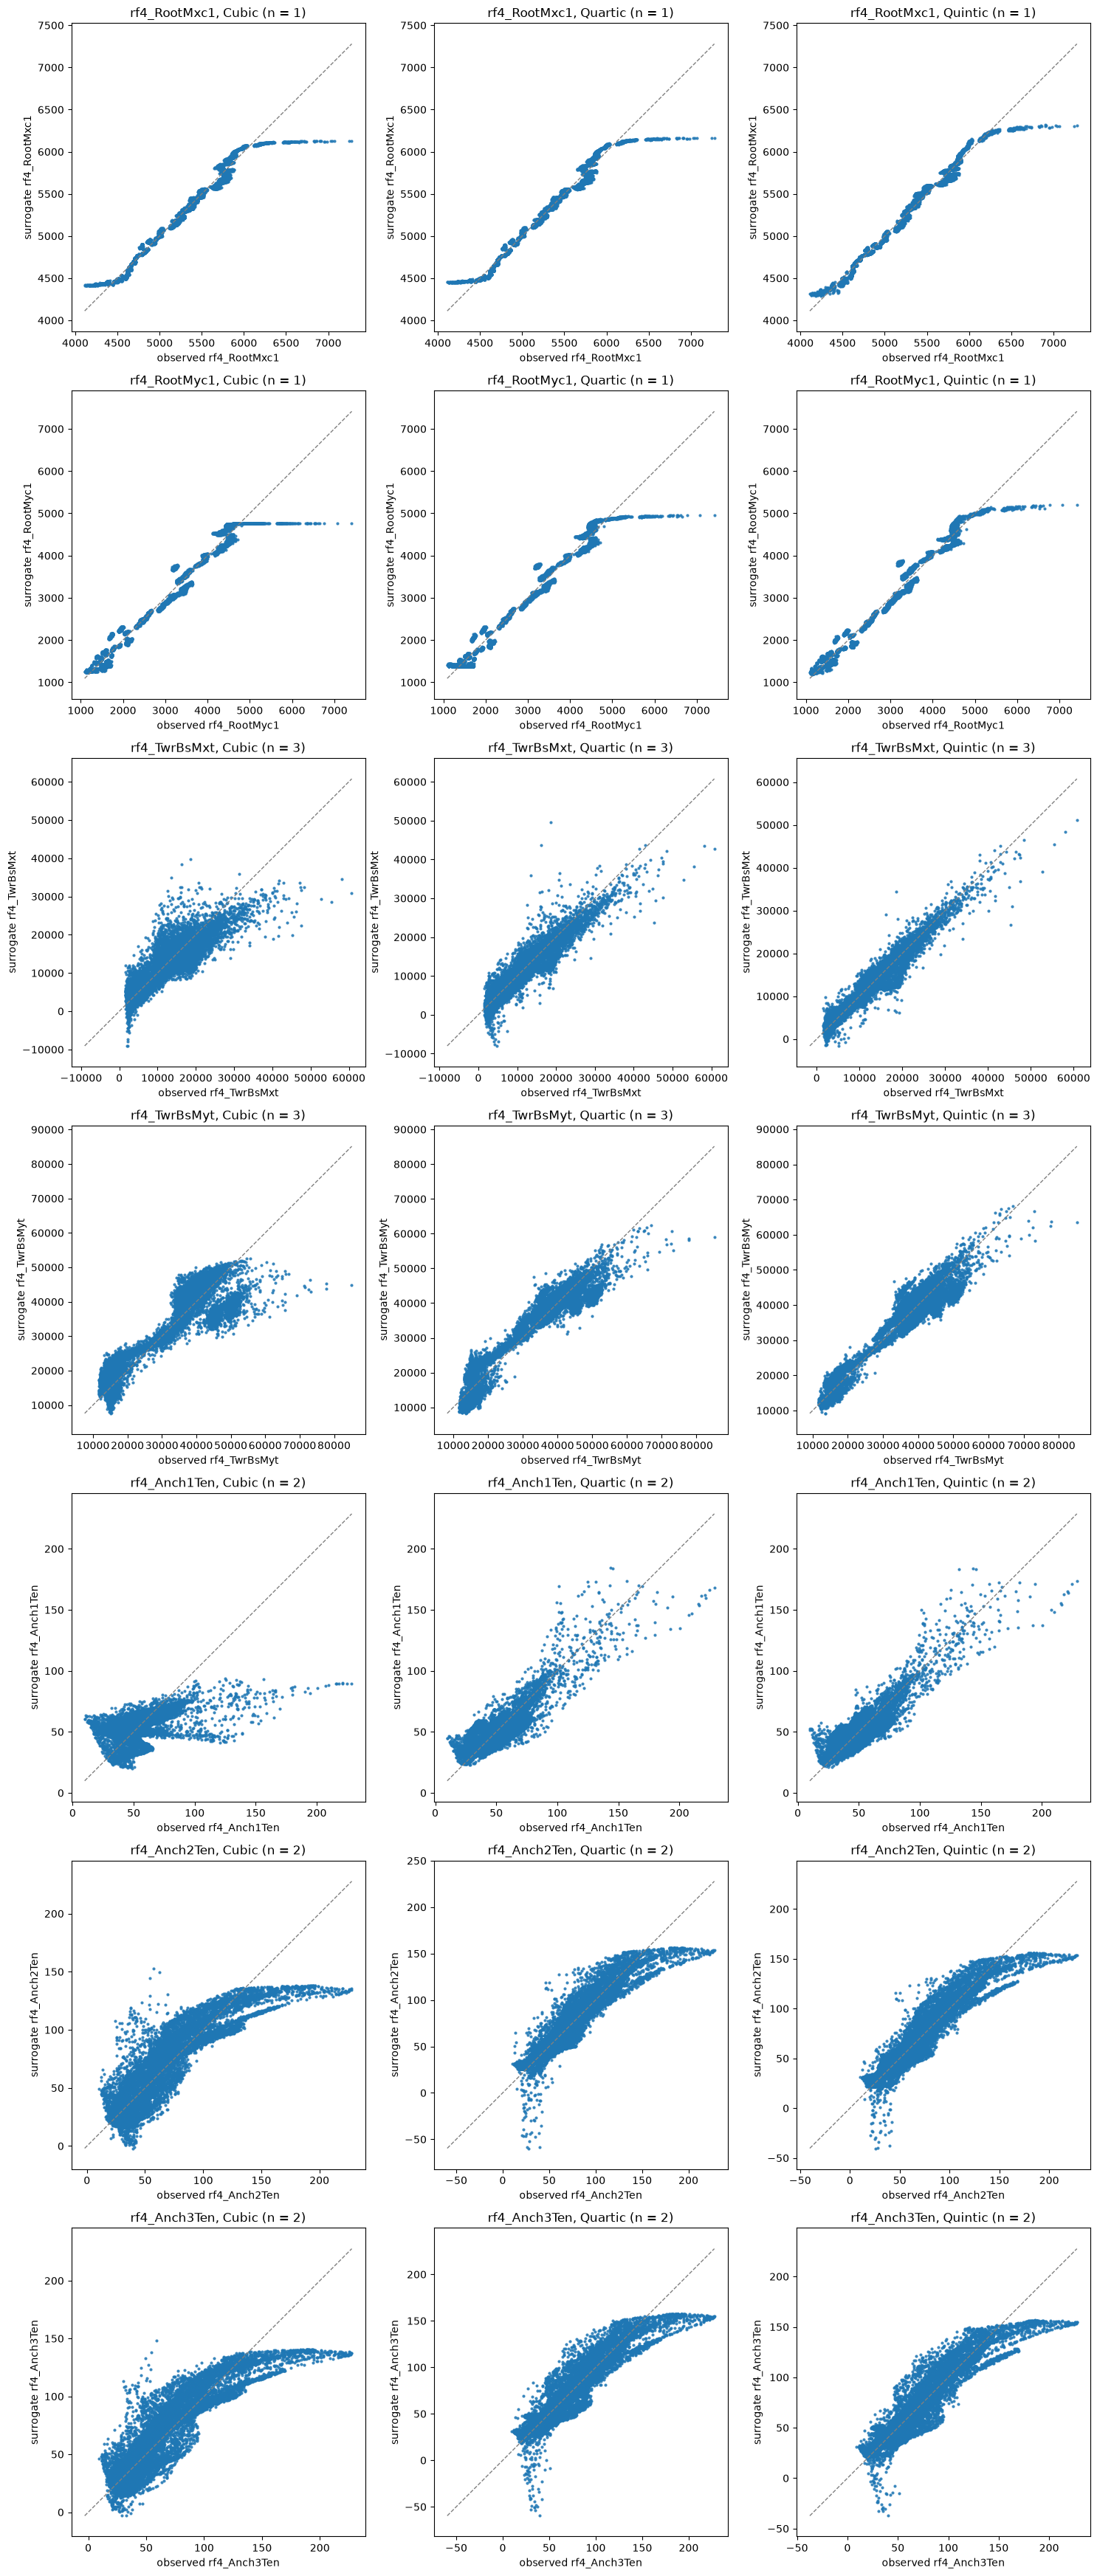

In [9]:
r2_2016 = np.array([[0.9745, 0.9751, 0.9825], [0.9693, 0.972, 0.975], [0.732, 0.868, 0.9403],
                    [0.7958, 0.903, 0.92], [0.209, 0.7271, 0.7456], [0.761, 0.8628, 0.8719],
                    [0.7712, 0.8483, 0.8586]])
degrees = (3, 4, 5)
models = ['Cubic', 'Quartic', 'Quintic']
surr = {}
r2_loo, r2_in = np.empty((7, 3)), np.empty((7, 3))
for i, name in enumerate(out_labels):
    f = F[:, i]
    for j, deg in enumerate(degrees):
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            s = ac.fit_surrogate(X=X, f=f, subspace=subs_n[i], kind='poly', degree=deg, qoi=name)
        for w in caught:
            print(f'{name}, degree {deg}: {getattr(w.message, "code", w.category.__name__)}')
        surr[i, j] = s
        r2_loo[i, j] = s.loo_r_squared
        r2_in[i, j] = 1 - np.sum((f - ac.predict(s, X))**2) / np.sum((f - f.mean())**2)

print('R^2 of the polynomial surrogates: leave-one-out / in-sample / 2016 notebook (in-sample)\n')
print(f'{"output":>14}{"n":>3}' + ''.join(f'{mod:>24}' for mod in models))
for i, name in enumerate(out_labels):
    print(f'{name:>14}{dims[i]:3d}' + ''.join(f'{r2_loo[i, j]:10.4f} /{r2_in[i, j]:6.3f} /{r2_2016[i, j]:6.3f}'
                                              for j in range(3)))
print(f'\nlargest |LOO - 2016| = {np.abs(r2_loo - r2_2016).max():.4f}; '
      f'every LOO R^2 >= the 2016 value: {bool((r2_loo >= r2_2016).all())}; '
      f'largest |in-sample - LOO| = {np.abs(r2_in - r2_loo).max():.1e}')

fig, axes = plt.subplots(7, 3, figsize=(15, 35))
for i, name in enumerate(out_labels):
    for j in range(3):
        ax = axes[i, j]
        ac.plotting.plot_surrogate_fit(surr[i, j], X=X[mask], f=F[mask, i], qoi_label=name, ax=ax,
                                       scatter_kw={'s': 4})
        ax.set_title(f'{name}, {models[j]} (n = {dims[i]})')
fig.tight_layout()
plt.show()

Most of the fits are tight. With the quintic model, four outputs have leave-one-out $R^2$ above 0.90 (`RootMxc1` 0.9833, `RootMyc1` 0.9756, `TwrBsMxt` 0.9417, `TwrBsMyt` 0.9251), the anchor 2 and 3 tensions are above 0.86, and `Anch1Ten` is the worst at 0.7757, with a poor cubic fit (0.2113). For the blade-root moments, the polynomials level off at the largest loads. The summary plots show why: those loads come from a steep rise at the highest wind speeds (the right end of the one-dimensional plots), which a polynomial of degree 5 or less cannot follow. Every leave-one-out $R^2$ is at least the 2016 value, and they differ from it by at most 0.0301. With 50,000 samples and at most 56 polynomial coefficients, the leave-one-out and in-sample $R^2$ agree to within 7.8e-04.

### Conclusions

Most of the outputs we examine have useful low-dimensional structure, but mostly of a simple kind. For three outputs (both blade-root moments and the tower-base fore-aft moment) the dominant direction is the wind-speed axis, and for the three anchor tensions the active subspace is the plane of `PlatformDir` and `Vhub`. Only the tower-base side-to-side moment has an oblique active direction, which mixes wind speed and wave direction. The surrogate models developed for these outputs could be used in applications such as optimization, integration and inversion. With 50,000 samples in only 5 dimensions, more traditional methods could be used too; for models with more inputs or more expensive runs, such a full parameter study would not be feasible, and active subspaces can reduce the dimension enough to make it so.

In [10]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 35 s
